### Tổng quan về tập dữ liệu mua sắm tại siêu thị.

- Đây là dữ liệu giao dịch bán lẻ trực tuyến, ghi lại các đơn hàng từ một cửa hàng bán đồ gia dụng, quà tặng, trang trí... trong khoảng thời gian 2010–2011.

#### Các biến đầu vào

- `InvoiceNo`: Mã hóa đơn (bắt đầu bằng "C" là đơn hủy)
- `StockCode`: Mã sản phẩm
- `Description`:	Tên mô tả sản phẩm
- `Quantity`:	Số lượng sản phẩm trong giao dịch (có thể âm nếu là hủy hàng)
- `InvoiceDate`:	Thời gian giao dịch
- `UnitPrice`:	Giá tiền trên một đơn vị sản phẩm
- `CustomerID`:	Mã khách hàng (có giá trị null)
- `Country`:	Quốc gia của khách hàng

#### Import thư viện và load dữ liệu

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# data = pd.read_excel('data/OnlineRetail.xlsx')
# data.to_csv('OnlineRetail.csv', index=False)
data = pd.read_csv('data/OnlineRetail.csv')


#### Kiểm tra vài dòng dữ liệu

In [ ]:
data.shape

(541909, 8)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
data.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [ ]:
data.tail(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [ ]:
data.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-10-31 14:41:00,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


#### Biểu đồ biểu thị sơ bộ dữ liệu

<Axes: xlabel='Quantity'>

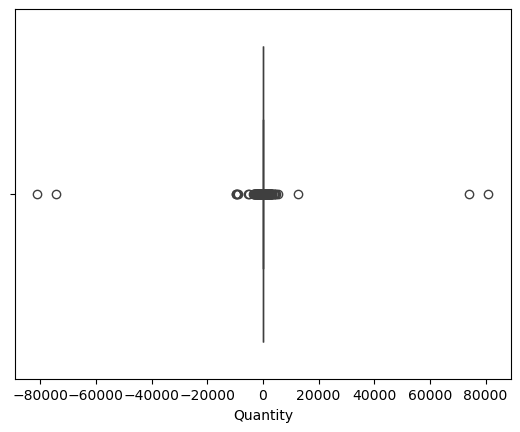

In [ ]:
sns.boxplot(x=data["Quantity"])

*Quantity* có nhiều giá trị âm và cực lớn, gây lệch phân phối mạnh.
Cần xem xét loại bỏ các dòng Quantity ≤ 0 và giới hạn outlier để phản ánh chính xác số lượng bán thực tế.

<Axes: xlabel='UnitPrice'>

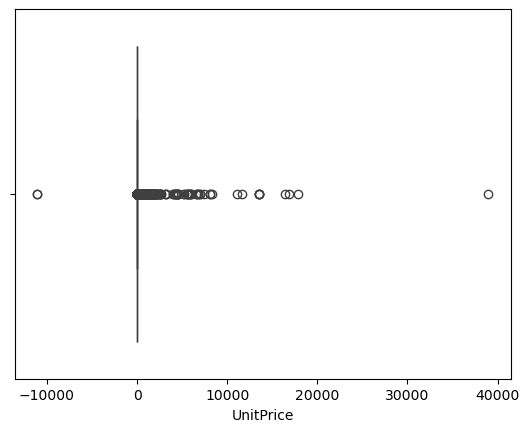

In [ ]:
sns.boxplot(x=data["UnitPrice"])

*UnitPrice* có phân phối lệch phải rõ rệt, tồn tại giá trị âm và nhiều giá trị cực cao bất thường.
-> Cần xử lý giá âm và outlier trước khi tính thống kê hoặc phân tích doanh thu.

<Axes: ylabel='Country'>

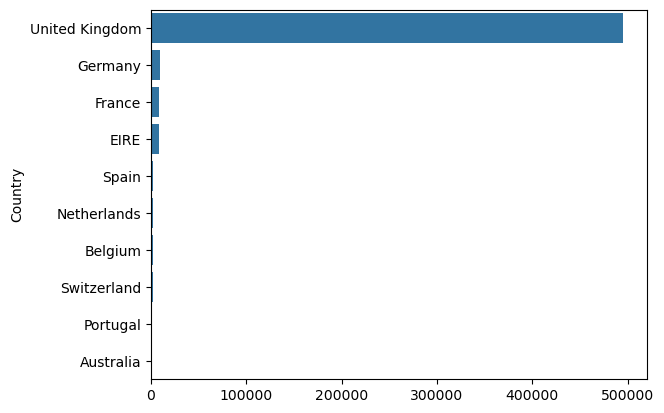

In [ ]:
top_countries = data["Country"].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index)

Dữ liệu bán hàng chủ yếu đến từ United Kingdom, các quốc gia khác chỉ chiếm tỷ trọng rất nhỏ.

<Axes: xlabel='Year'>

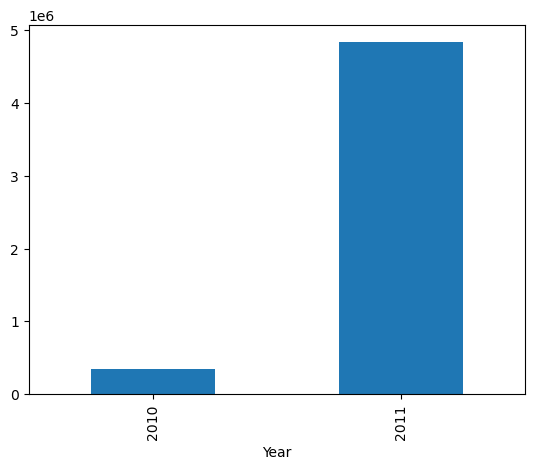

In [ ]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
data["Year"] = data["InvoiceDate"].dt.year
data.groupby("Year")["Quantity"].sum().plot(kind="bar")


Dữ liệu năm 2010 chỉ là giai đoạn cuối năm, nên số lượng giao dịch thấp hơn nhiều so với 2011.

#### Tiền xử lý dữ liệu

##### Loại bỏ dòng trùng lặp

In [ ]:
df1 = data
print(f"\nSố dòng trùng lặp: {df1.duplicated().sum()}")
df1 = df1.drop_duplicates()


Số dòng trùng lặp: 5268


##### Xử lý missing values

In [ ]:
print(df1.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Year                0
dtype: int64


Ta thấy số lượng dữ liệu trống khá nhiều ở cột Description và CustomerID.

- **CustomerID** NaN có thể là khách vãng lai.
- **Description** sẽ tìm tương ứng theo StockCode của nó.

In [ ]:
# Tạo mapping từ StockCode sang Description phổ biến nhất
desc_mapping = df1[df1['Description'].notnull()].groupby('StockCode')['Description'].agg(
    lambda x: x.value_counts().index[0] if len(x.value_counts()) > 0 else None
)

# Thay thế Description null
initial_null = df1['Description'].isnull().sum()
df1.loc[:, "Description"] = df1.apply(
    lambda row: desc_mapping.get(row["StockCode"], row["Description"])
    if pd.isna(row["Description"]) else row["Description"],
    axis=1
)


# Kết quả
final_null = df1['Description'].isnull().sum()
print(f"Đã thay thế: {initial_null - final_null} Description null")
print(f"Description null còn lại: {final_null}")

# StockCode không tồn tại
nonexistent = df1[df1['Description'].isnull()]['StockCode'].unique()
print(f"StockCode không tồn tại Description tương ứng: {len(nonexistent)}")
print(f"Danh sách: {nonexistent}")

Đã thay thế: 1342 Description null
Description null còn lại: 112
StockCode không tồn tại Description tương ứng: 112
Danh sách: ['21134' '85226A' '85044' '20950' '84670' '35951' '21653' '20849' '72803B'
 '85018C' '62095B' '72814' '84247C' '90042B' '21431' '21589' '84546'
 '17011A' '84455' '84967A' '84967B' '84966B' '84966A' 'DCGS0055'
 'DCGS0072' 'DCGS0074' '20864' '21282' '21805' '22143' '35644' '35991'
 '84424A' '84509F' '84526' '84664' '84964B' '85110' '85179B' '90000C'
 '90095' '90091' 'DCGS0057' '35969' '20738' '20689' '47563B' '37477D'
 '84559D' '35823P' '20850' '21283' '22036' '79172D' '72800F' '72781'
 '35015' '72793' '72789' '85018B' '35824B' '84726' '84875A' '84876C'
 '84845D' '21274' '21474' '10134' '21511' '82545A' '84251F' '35603B'
 '47502' '84007' '21337' '46037A' '84251J' '40018F' '84864A' '21825'
 '10123G' '84899F' '20863' '21923' '20896' '20825' '85060' '35594' '21330'
 '78027' '21806' '85226C' '47591A' '37424' '90037D' '84857A' '84482'
 '21854' '16053' '84797B' 'DCGS00

In [ ]:
# Xóa các dòng có StockCode không tồn tại Description
df1 = df1[~df1['StockCode'].isin(nonexistent)]

In [ ]:
# Kiểm tra lại xem Description null có còn không
df1[df1['Description'].isnull()].head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year


##### Thêm cột Year và TotalAmount để hỗ trợ trực quan hóa

In [ ]:
df1["TotalAmount"] = df1["Quantity"] * df1["UnitPrice"]
df1["Year"] = df1["InvoiceDate"].dt.year
print(df1.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Year  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  2010   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  2010   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  2010   

   TotalAmount  
0        15.30  
1        20.34  
2        22.00  
3        20.34  
4        20.34  


##### Xử lý giá trị bất thường

Chia bộ dữ liệu ra làm 2 nhóm : Đơn bán (sales_df) và Đơn hoàn (returns_df) dựa trên Quantity và InvoiceNo

In [ ]:
returns_df = df1[
    (df1["Quantity"] < 0) |
    (df1["InvoiceNo"].astype(str).str.contains("C", na=False))
].copy()
print("Số đơn hoàn hàng:", len(returns_df))
returns_df.head(5)

Số đơn hoàn hàng: 10490


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,TotalAmount
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,2010,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,2010,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,2010,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,2010,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,2010,-6.96


In [ ]:
sales_df = df1[
    (df1["Quantity"] > 0) &
    (~df1["InvoiceNo"].astype(str).str.contains("C", na=False))
].copy()
print("Số đơn hợp lệ:", len(sales_df))
sales_df.head(5)

Số đơn hợp lệ: 526039


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,20.34


Loại bỏ các *Unit Price* <= 0 và các outlier có giá trị lớn hơn phân vị 99% của dữ liệu

In [ ]:
q_hi_price = sales_df["UnitPrice"].quantile(0.99)
# Giữ lại các đơn hàng có UnitPrice <= ngưỡng này
sales_df = sales_df[(sales_df["UnitPrice"] > 0) & (sales_df["UnitPrice"] < q_hi_price)].copy()

print(q_hi_price)
print(df1["UnitPrice"].describe())

16.98
count    536529.000000
mean          4.633623
std          97.243243
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


Loại bỏ các outlier của Quantity

In [ ]:
q_hi_qty   = sales_df["Quantity"].quantile(0.99)
q_low_qty   = sales_df["Quantity"].quantile(0.1)

q_high_qty = sales_df["Quantity"].quantile(0.99)   # ngưỡng trên 99%
sales_df = sales_df[(sales_df["Quantity"] >= q_low_qty) & (sales_df["Quantity"] <= q_high_qty)]

print(df1["Quantity"].describe())

count    536529.000000
mean          9.623748
std         219.152755
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64


#### Trực quan hóa dữ liệu bán hàng

##### Phân bố Quantity và UnitPrice

<Axes: xlabel='Quantity'>

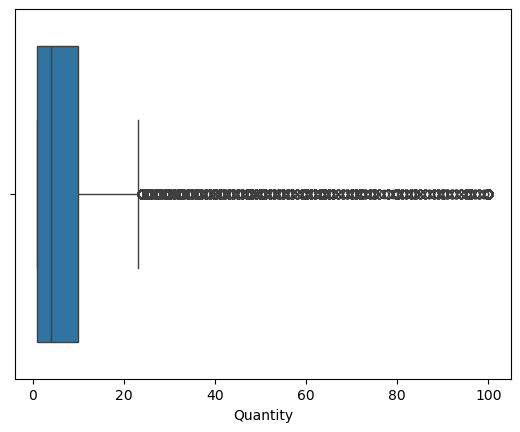

In [ ]:
sns.boxplot(x=sales_df["Quantity"])

<Axes: xlabel='UnitPrice'>

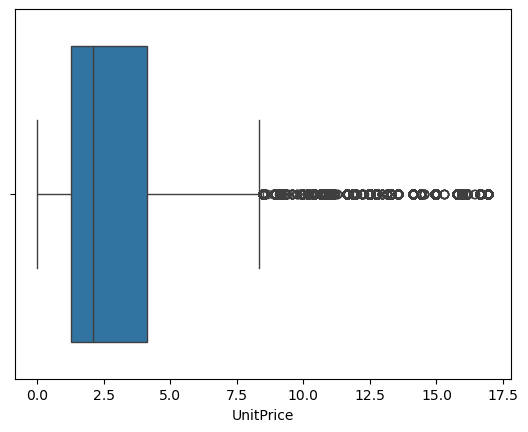

In [ ]:
sns.boxplot(x=sales_df["UnitPrice"])

##### Tỷ lệ theo quốc gia (Country)

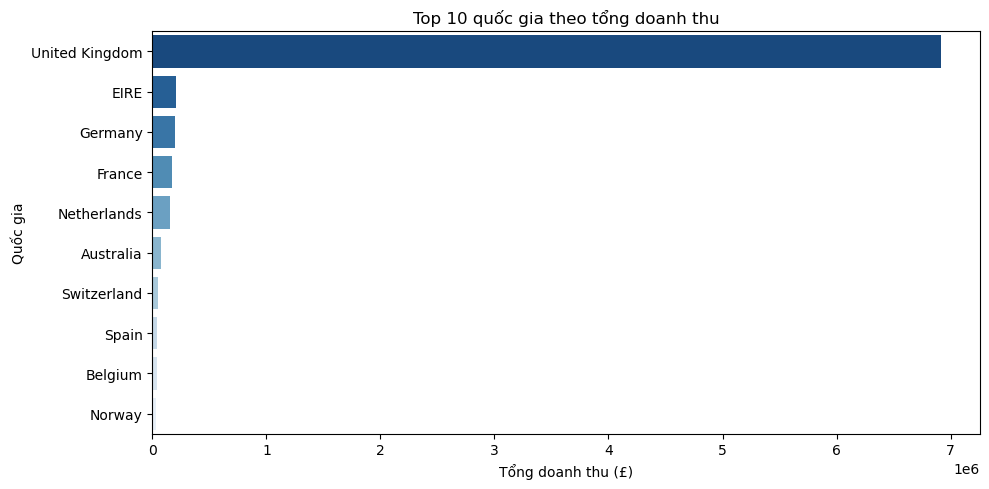

In [ ]:
# Tổng doanh thu theo quốc gia
country_sales = (
    sales_df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)   # chỉ lấy top 10 quốc gia
)

plt.figure(figsize=(10,5))
sns.barplot(x=country_sales.values, y=country_sales.index, hue = country_sales.index, palette="Blues_r",legend = False)
plt.title("Top 10 quốc gia theo tổng doanh thu")
plt.xlabel("Tổng doanh thu (£)")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

##### Top 10 sản phẩm bán chạy

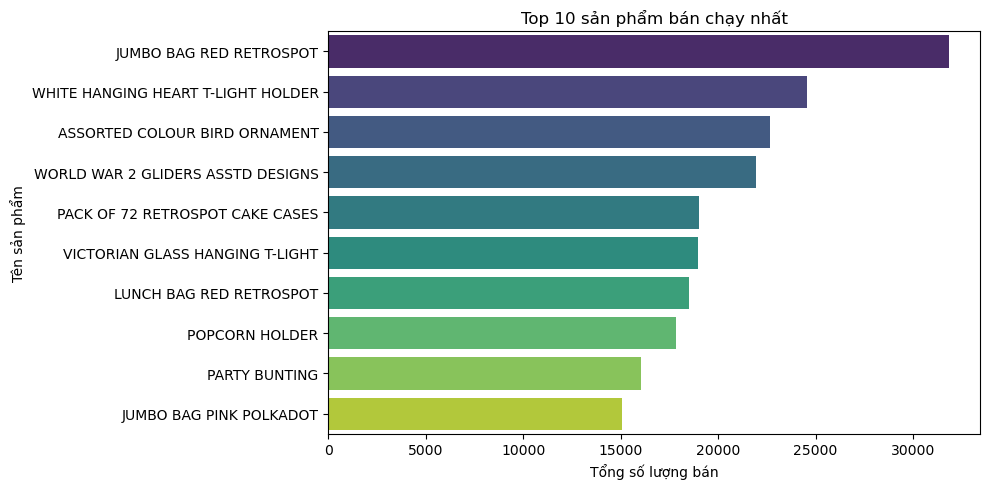

In [ ]:
# Top 10 sản phẩm theo số lượng bán ra
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=top_products.values, y=top_products.index, hue = top_products.index, palette="viridis", legend = False)
plt.title("Top 10 sản phẩm bán chạy nhất")
plt.xlabel("Tổng số lượng bán")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()


##### Doanh thu theo năm / tháng

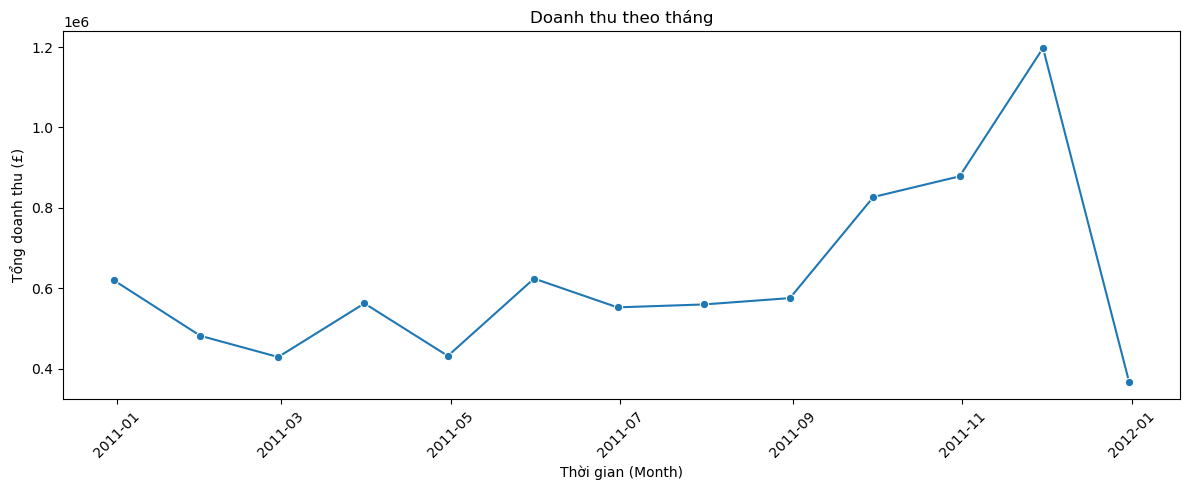

In [ ]:
# Đảm bảo kiểu dữ liệu đúng
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"], errors="coerce")
sales_df["TotalAmount"] = pd.to_numeric(sales_df["TotalAmount"], errors="coerce")

# Gộp theo tháng bằng Grouper (ra datetime cuối tháng)
monthly_sales = (
    sales_df.set_index("InvoiceDate")
            .groupby(pd.Grouper(freq="ME"))["TotalAmount"]
            .sum()
            .reset_index()
)

# Vẽ
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly_sales, x="InvoiceDate", y="TotalAmount", marker="o")
plt.title("Doanh thu theo tháng")
plt.xlabel("Thời gian (Month)")
plt.ylabel("Tổng doanh thu (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Phân phối số lượng giao dịch trong ngày

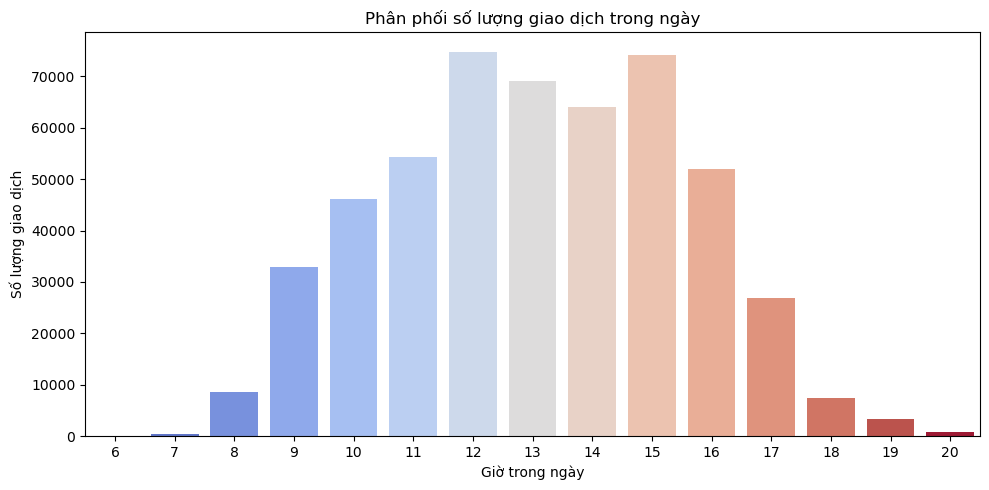

In [ ]:
# Rút giờ từ InvoiceDate
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

plt.figure(figsize=(10,5))
sns.countplot(x="Hour", hue="Hour", data=sales_df, palette="coolwarm", legend=False)
plt.title("Phân phối số lượng giao dịch trong ngày")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Số lượng giao dịch")
plt.tight_layout()
plt.show()


##### Quan hệ giữa Quantity, UnitPrice, TotalAmount

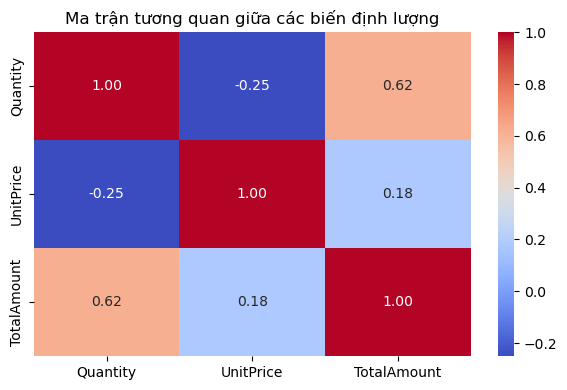

In [ ]:
num_cols = ["Quantity", "UnitPrice", "TotalAmount"]

# Ma trận tương quan
corr = sales_df[num_cols].corr()

# Vẽ heatmap
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan giữa các biến định lượng")
plt.tight_layout()
plt.show()

- Ma trận tương quan cho thấy TotalAmount (doanh thu) có mối liên hệ chặt chẽ hơn với Quantity so với UnitPrice.
=> Điều này phản ánh rằng số lượng sản phẩm bán ra là yếu tố chính ảnh hưởng đến doanh thu, trong khi đơn giá chỉ đóng vai trò phụ.
- Mối quan hệ âm nhẹ giữa Quantity và UnitPrice cho thấy xu hướng các mặt hàng giá thấp có thể được mua với số lượng lớn hơn.

#### Trực quan hóa dữ liệu trả hàng

##### Tỉ lệ hoàn hàng theo quốc gia

In [ ]:
returns_df["RefundAmount"] = abs(returns_df["Quantity"] * returns_df["UnitPrice"])
sales_df["SalesAmount"] = sales_df["Quantity"] * sales_df["UnitPrice"]

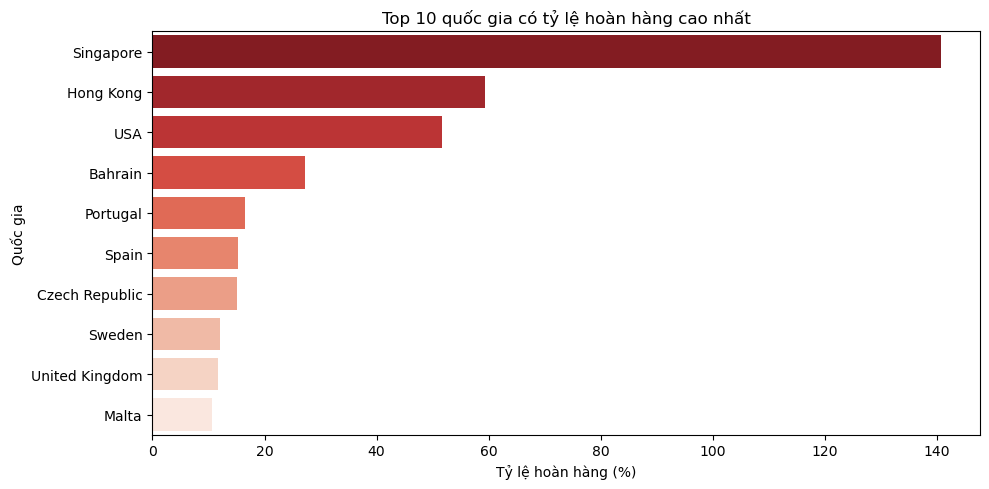

In [ ]:
sales_by_country = (
    sales_df.groupby("Country")["TotalAmount"].sum().reset_index(name="SalesAmount")
)
refund_by_country = (
    returns_df.groupby("Country")["RefundAmount"].sum().reset_index(name="RefundAmount")
)

# Gộp hai bảng lại
refund_rate_country = pd.merge(sales_by_country, refund_by_country, on="Country", how="left")
refund_rate_country["RefundAmount"] = refund_rate_country["RefundAmount"].fillna(0)

# Tính tỷ lệ hoàn hàng (%)
refund_rate_country["RefundRate(%)"] = (
    refund_rate_country["RefundAmount"] / refund_rate_country["SalesAmount"] * 100
)

# Lấy top 10 quốc gia có tỷ lệ hoàn hàng cao nhất
top_refund_rate = refund_rate_country.sort_values("RefundRate(%)", ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(
    data=top_refund_rate,
    x="RefundRate(%)",
    y="Country",
    hue="Country",
    palette="Reds_r",
    legend = False
)
plt.title("Top 10 quốc gia có tỷ lệ hoàn hàng cao nhất")
plt.xlabel("Tỷ lệ hoàn hàng (%)")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

##### Top sản phẩm bị hoàn nhiều nhất

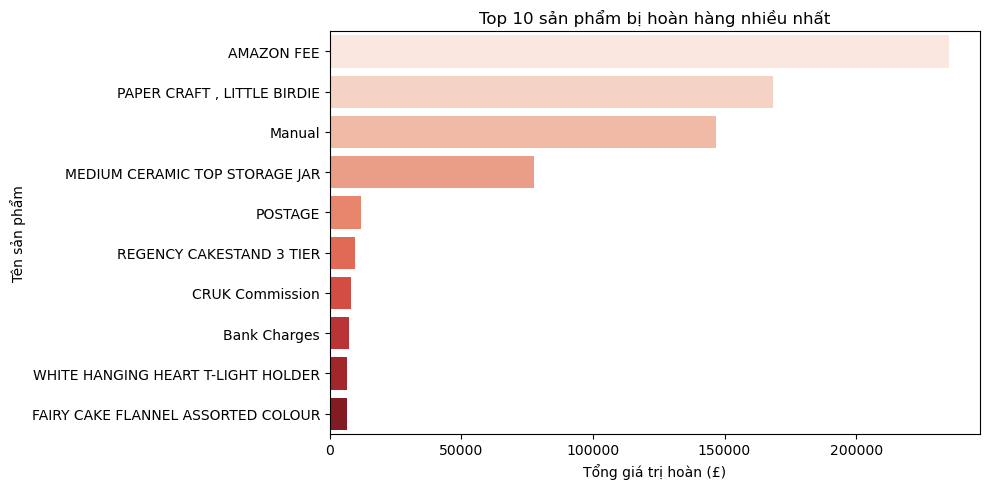

In [ ]:
top_refund_products = (
    returns_df.groupby("Description")["RefundAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(
    x=top_refund_products.values,
    y=top_refund_products.index,
    hue=top_refund_products.index,
    palette="Reds",
    legend=False
)
plt.title("Top 10 sản phẩm bị hoàn hàng nhiều nhất")
plt.xlabel("Tổng giá trị hoàn (£)")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()
